## **1. Import Statements and Loading Data**

### **1.1 Import Statements**

In [1]:
from pathlib import Path
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
import lightgbm as lgb

from IPython.display import display, Markdown
from scipy.sparse.csgraph import connected_components
from scipy.special import logit
from scipy.stats import norm, rankdata
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from threadpoolctl import threadpool_limits
from sklearn.tree import DecisionTreeClassifier

### **1.2 Loading Data and Other Configurations**

In [2]:
ROOT = Path.cwd()
DATA = ROOT / 'data'
SEED = 42
THREADS = 8
VALIDATION_NET_SEEDS = 3
FINAL_NET_SEEDS = 40
NET_EPOCHS = 150

torch.set_num_threads(THREADS)
CPU_LIMIT = threadpool_limits(limits=THREADS)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': False})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 35)

train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
edges = pd.read_csv(DATA / 'txs_edgelist.csv')
sample = pd.read_csv(DATA / 'sample_submission.csv')

FEATURES = [column for column in train if column.startswith('feat_')]
known = train.dropna(subset=['label']).copy()
known['label'] = known['label'].astype(int)
all_rows = pd.concat([train[['txId', 'time_step', *FEATURES]],
                      test[['txId', 'time_step', *FEATURES]]], ignore_index=True)

## **2. Data Audit**

In [3]:
dataset_sizes = pd.DataFrame([
    {'dataset': name, 'rows': len(frame), 'columns': frame.shape[1],
     'missing_values': int(frame.isna().sum().sum())}
    for name, frame in [('train', train), ('test', test), ('edges', edges)]
])
display(dataset_sizes)

missing = train.isna().sum()
display(missing[missing > 0].rename('missing_rows').to_frame())

id_checks = pd.Series({
    'Duplicate train txId': int(train['txId'].duplicated().sum()),
    'Duplicate test txId': int(test['txId'].duplicated().sum()),
    'Shared train/test txId': len(set(train['txId']) & set(test['txId'])),
}, name='count')
display(id_checks.to_frame())

,dataset,rows,columns,missing_values
0,train,141772,168,110537
1,test,15329,168,0
2,edges,234355,2,0


,missing_rows
label,110537


,count
Duplicate train txId,0
Duplicate test txId,0
Shared train/test txId,0


## **3. Exploratory Data Analysis**

### **3.1 Label Counts**

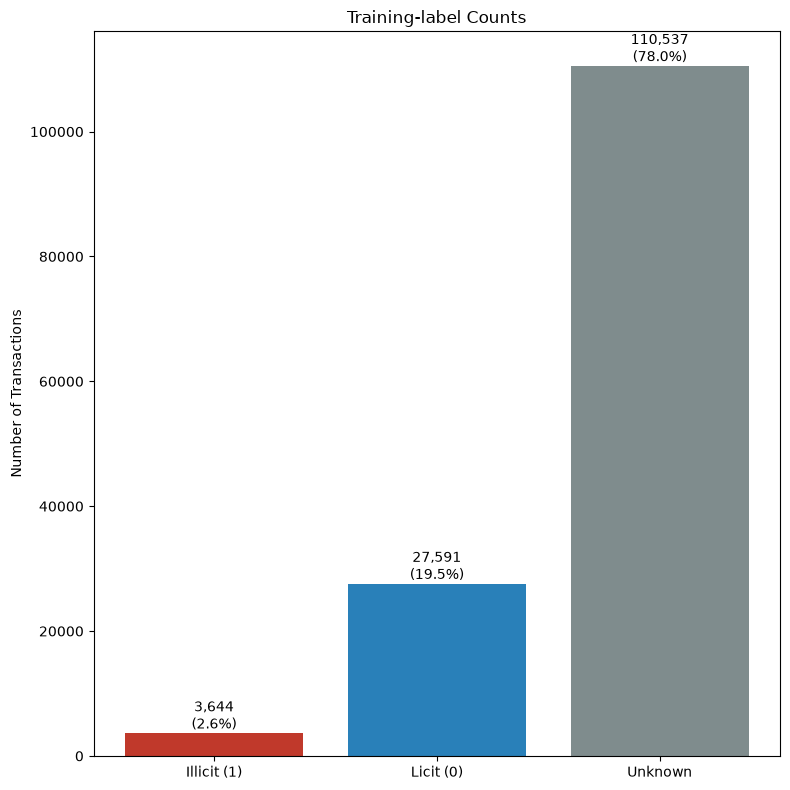

In [4]:
label_counts = train['label'].value_counts(dropna=False)
labels = ['Illicit (1)', 'Licit (0)', 'Unknown']
counts = [label_counts.get(1.0, 0), label_counts.get(0.0, 0), int(train['label'].isna().sum())]
colours = ['#c0392b', '#2980b9', '#7f8c8d']

fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.bar(labels, counts, color=colours)
ax.set_title('Training-label Counts')
ax.set_ylabel('Number of Transactions')

for bar, count in zip(bars, counts):
    percentage = 100 * count / len(train)
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{count:,}\n({percentage:.1f}%)', ha='center', va='bottom')

plt.tight_layout()
plt.show()

### **3.2 Labels and Time Coverage**

time_step,known_rows,illicit_count,illicit_rate
1,"2,147",17,0.79%
2,"1,117",18,1.61%
3,"1,279",11,0.86%
4,"1,440",30,2.08%
5,"1,882",8,0.43%
6,485,5,1.03%
7,"1,203",102,8.48%
8,"1,165",67,5.75%
9,778,248,31.88%
10,972,18,1.85%


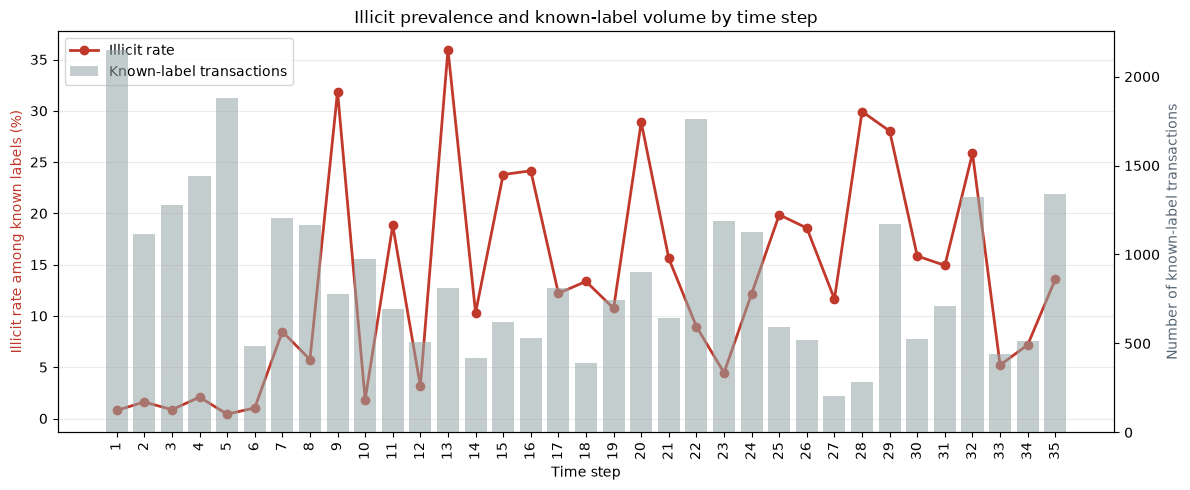

In [5]:
prevalence_by_time = (known.groupby('time_step')['label']
                      .agg(known_rows='size', illicit_count='sum', illicit_rate='mean')
                      .reset_index())

display(
    prevalence_by_time.style
    .format({'known_rows': '{:,}', 'illicit_count': '{:,}', 'illicit_rate': '{:.2%}'})
    .hide(axis='index')
)

fig, ax_rate = plt.subplots(figsize=(12, 5))
ax_count = ax_rate.twinx()

ax_count.bar(prevalence_by_time['time_step'], prevalence_by_time['known_rows'],
             color='#95a5a6', alpha=0.55, label='Known-label transactions')
ax_rate.plot(prevalence_by_time['time_step'], prevalence_by_time['illicit_rate'] * 100,
             color='#c0392b', marker='o', linewidth=2, label='Illicit rate')

ax_rate.set_title('Illicit prevalence and known-label volume by time step')
ax_rate.set_xlabel('Time step')
ax_rate.set_ylabel('Illicit rate among known labels (%)', color='#c0392b')
ax_count.set_ylabel('Number of known-label transactions', color='#566573')
ax_rate.set_xticks(prevalence_by_time['time_step'])
ax_rate.tick_params(axis='x', rotation=90)
ax_rate.grid(axis='y', alpha=0.25)

handles_1, labels_1 = ax_rate.get_legend_handles_labels()
handles_2, labels_2 = ax_count.get_legend_handles_labels()
ax_rate.legend(handles_1 + handles_2, labels_1 + labels_2, loc='upper left')
plt.tight_layout()
plt.show()

**Findings:** The illicit share among known labels swings from **0.43%** (step 5) to **36.0%** (step 13), around an overall **11.7%**, and the number of known labels per step ranges from 206 to 2,147. Illicit rows are a minority, so the models weight them up by inverse class frequency (`sample_weights`, Section 5). The share also changes sharply over time, which motivates evaluating across several temporal folds (Section 4) and the recency weighting compared in Section 7.

### **3.3 Time Coverage for Train vs Test**

Train time-step range: 1 to 35
Test time-step range: 36 to 49


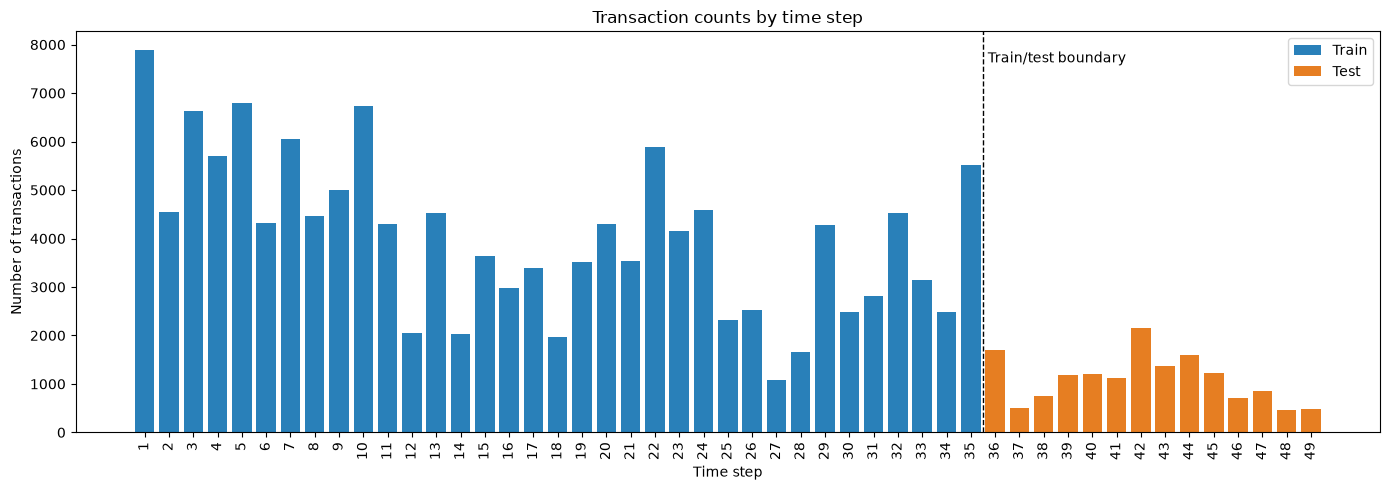

In [6]:
train_time_counts = train['time_step'].value_counts().sort_index()
test_time_counts = test['time_step'].value_counts().sort_index()

print(f'Train time-step range: {train_time_counts.index.min()} to {train_time_counts.index.max()}')
print(f'Test time-step range: {test_time_counts.index.min()} to {test_time_counts.index.max()}')

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(train_time_counts.index, train_time_counts.values, color='#2980b9', label='Train')
ax.bar(test_time_counts.index, test_time_counts.values, color='#e67e22', label='Test')
ax.axvline(train['time_step'].max() + 0.5, color='black', linestyle='--', linewidth=1)
ax.text(train['time_step'].max() + 0.7, ax.get_ylim()[1] * 0.95, 'Train/test boundary', va='top')
ax.set_title('Transaction counts by time step')
ax.set_xlabel('Time step')
ax.set_ylabel('Number of transactions')
ax.set_xticks(range(int(train_time_counts.index.min()), int(test_time_counts.index.max()) + 1))
ax.tick_params(axis='x', rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

**Findings:** Training covers steps 1–35 and the test set steps 36–49, with no overlap. A random split would let a model learn from later periods than the ones it predicts, so Section 4 validates by training on earlier steps and predicting the following 14 steps, the same horizon as the test set.

### **3.4 Summary Statistics**

In [7]:
summary_statistics = train[FEATURES].describe().T
display(summary_statistics.round(3))

,count,mean,std,min,25%,50%,75%,max
feat_1,141772.0,0.018,1.120,-0.173,-0.172,-0.169,-0.136,71.682
feat_2,141772.0,-0.108,0.395,-0.211,-0.185,-0.159,-0.107,25.674
feat_3,141772.0,-0.300,0.961,-1.756,-1.201,-0.646,0.464,2.129
feat_4,141772.0,-0.003,0.990,-0.122,-0.122,-0.122,-0.047,49.028
feat_5,141772.0,0.000,1.113,-0.064,-0.044,-0.044,-0.044,260.091
...,...,...,...,...,...,...,...,...
feat_161,141772.0,-0.022,1.088,-0.126,-0.087,-0.087,-0.087,251.849
feat_162,141772.0,-0.045,1.038,-0.131,-0.131,-0.131,-0.085,238.783
feat_163,141772.0,-0.050,0.790,-0.270,-0.141,-0.098,-0.098,105.734
feat_164,141772.0,0.028,0.968,-1.761,-0.121,-0.121,0.134,1.520


### **3.5 Cardinality and Potential Categorical Variables**

The main purpose of this check is to find features that may represent categories encoded as numbers.
List features with fewer than 100 distinct values and inspect some of their observed values.
Low cardinality can also come from counts or other discrete measurements, so these are candidates to inspect,
not confirmed categorical variables.

In [8]:
cardinality = train[FEATURES].nunique().sort_values()
categorical_candidates = cardinality[cardinality < 100].rename('unique_values').to_frame()
categorical_candidates['example_values'] = [
    np.round(np.sort(train[column].dropna().unique())[:8], 6).tolist()
    for column in categorical_candidates.index
]
categorical_candidates.index.name = 'feature'
print(f'{len(categorical_candidates)} features have fewer than 100 distinct values.')
with pd.option_context('display.max_colwidth', None):
    display(categorical_candidates)

7 features have fewer than 100 distinct values.


,unique_values,example_values
feature,,
feat_112,8,"[-1.626385, -1.096336, -0.566287, -0.036238, 0.493811, 1.02386, 1.553909, 2.083958]"
feat_113,8,"[-1.781034, -1.26734, -0.753646, -0.239953, 0.273741, 0.787435, 1.301128, 1.814822]"
feat_3,8,"[-1.756361, -1.201369, -0.646376, -0.091383, 0.463609, 1.018602, 1.573595, 2.128587]"
feat_148,9,"[-1.51191, -0.968903, -0.425896, 0.117111, 0.660117, 1.203124, 1.746131, 2.289138]"
feat_149,9,"[-2.466561, -1.94385, -1.421138, -0.898426, -0.375715, 0.146997, 0.669709, 1.192421]"
feat_15,26,"[-0.013282, 0.159894, 0.333069, 0.506244, 0.679419, 0.852594, 1.198944, 1.37212]"
feat_160,54,"[-0.216057, -0.098889, 0.018279, 0.135448, 0.252616, 0.369784, 0.486952, 0.60412]"


**Findings:** Seven features have fewer than 100 distinct values (`feat_3`, `feat_112` and `feat_113` with 8; `feat_148` and `feat_149` with 9; `feat_15` with 26; `feat_160` with 54), and none is binary. Their observed values are evenly spaced numbers on a standardised scale, consistent with scaled counts or ordinal measurements rather than category codes. The models therefore use them as ordinary numeric features, without categorical encoding.

### **3.6 Skewness**

Skewness describes asymmetry in a feature's distribution. Compare train and test for the 20 features
with the largest absolute skewness in either dataset.

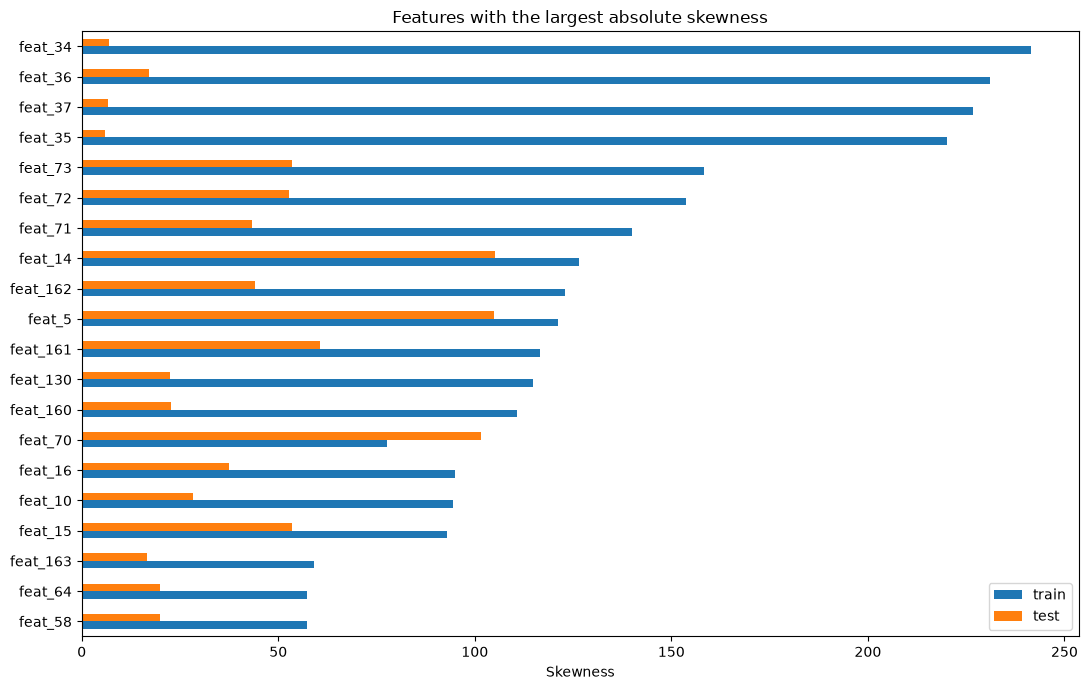

In [9]:
skewness = pd.DataFrame({'train': train[FEATURES].skew(), 'test': test[FEATURES].skew()})
plot_columns = skewness.abs().max(axis=1).nlargest(20).index
skewness.loc[plot_columns].iloc[::-1].plot.barh(figsize=(11, 7))
plt.title('Features with the largest absolute skewness')
plt.xlabel('Skewness')
plt.tight_layout()
plt.show()

**Findings:** Many features are heavily skewed: **68 of 165** have absolute skewness above 10 in training, up to **241.5** for `feat_34`, and the most skewed features differ sharply between train and test (for `feat_34` by 234.7). Tree models are unaffected by monotone rescaling, but neural networks are sensitive to extreme values, so the networks in Section 7 first pass their inputs through a `QuantileTransformer` that maps each feature to a normal distribution fitted on training rows.

### **3.7 Feature Correlation and Redundancy**

Pairs with absolute Pearson correlation of at least 0.95 may carry overlapping information. Show the 20 strongest pairs in a table and the features in the 15 strongest pairs in a heatmap.

103 feature pairs have |correlation| >= 0.95.


,feature_1,feature_2,absolute_correlation
3524,feat_24,feat_30,1.000000
7864,feat_59,feat_65,1.000000
3382,feat_23,feat_29,1.000000
7970,feat_60,feat_66,1.000000
8075,feat_61,feat_67,1.000000
3665,feat_25,feat_31,1.000000
3239,feat_22,feat_28,1.000000
7757,feat_58,feat_64,0.999992
3805,feat_26,feat_32,0.999506
3944,feat_27,feat_33,0.999490


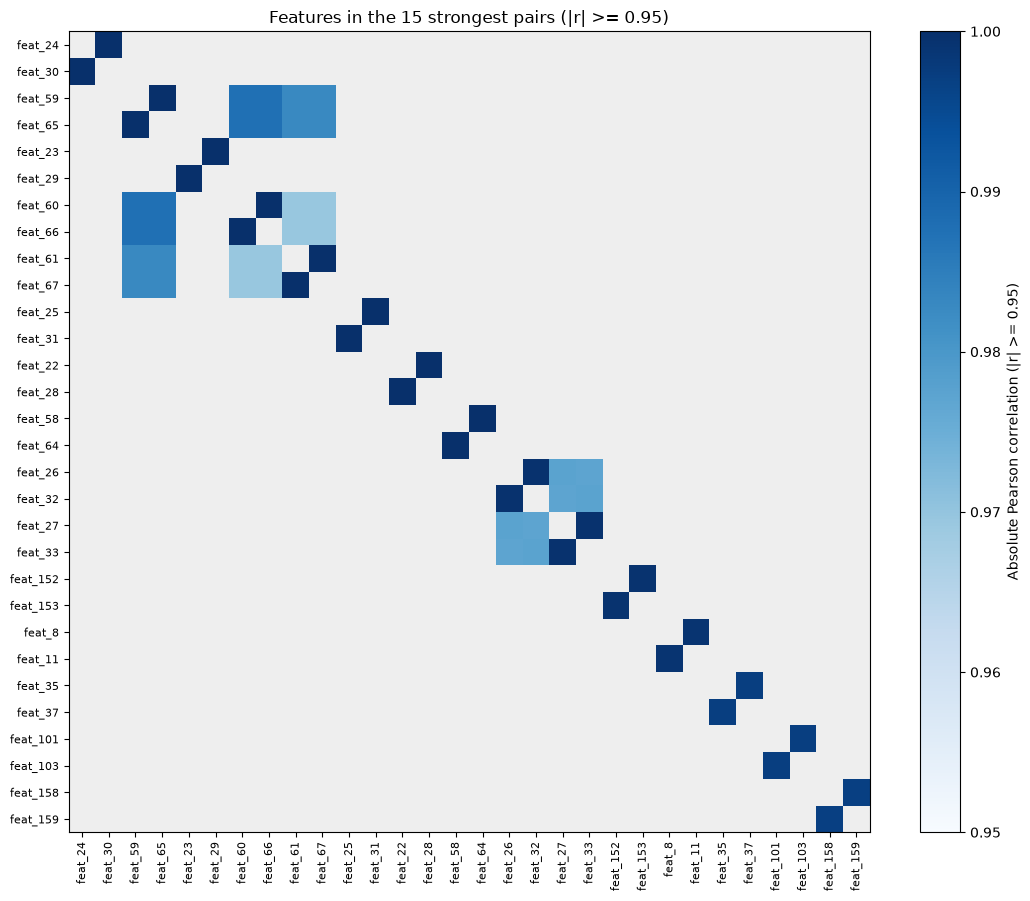

In [10]:
correlation = train[FEATURES].corr()
upper = correlation.abs().where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
correlated_pairs = (upper.stack().rename('absolute_correlation').reset_index()
                    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'}))
correlated_pairs = correlated_pairs.query('absolute_correlation >= 0.95').sort_values(
    'absolute_correlation', ascending=False)
print(f'{len(correlated_pairs):,} feature pairs have |correlation| >= 0.95.')
display(correlated_pairs.head(20))

if not correlated_pairs.empty:
    strongest_pairs = correlated_pairs.head(15)
    chart_features = pd.Index(pd.unique(
        strongest_pairs[['feature_1', 'feature_2']].to_numpy().ravel()
    ))
    chart_correlation = correlation.loc[chart_features, chart_features].abs()
    mask = (chart_correlation.to_numpy() < 0.95) | np.eye(len(chart_features), dtype=bool)
    chart_values = np.ma.masked_where(mask, chart_correlation.to_numpy())
    cmap = plt.get_cmap('Blues').copy()
    cmap.set_bad('#eeeeee')

    fig, ax = plt.subplots(figsize=(11, 9))
    image = ax.imshow(chart_values, cmap=cmap, vmin=0.95, vmax=1.0)
    ax.set_xticks(range(len(chart_features)), chart_features, rotation=90, fontsize=8)
    ax.set_yticks(range(len(chart_features)), chart_features, fontsize=8)
    ax.set_title(f'Features in the {len(strongest_pairs)} strongest pairs (|r| >= 0.95)')
    fig.colorbar(image, ax=ax, label='Absolute Pearson correlation (|r| >= 0.95)')
    plt.tight_layout()
    plt.show()

### **3.8 Individual Feature Signals**

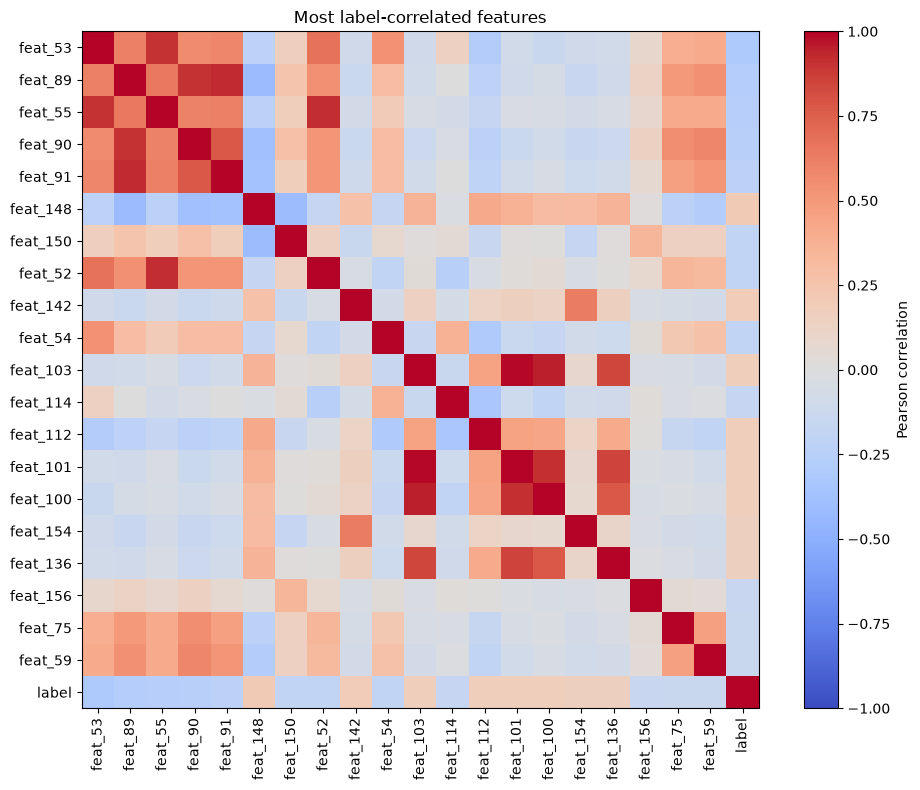

,feature,label_correlation,mutual_information,single_feature_auc
52,feat_53,-0.3076,0.2312,0.8568
64,feat_65,-0.1389,0.2235,0.6258
58,feat_59,-0.1389,0.2227,0.6258
54,feat_55,-0.2617,0.2222,0.8397
88,feat_89,-0.2664,0.2090,0.7937
66,feat_67,-0.1367,0.2086,0.5946
60,feat_61,-0.1367,0.2084,0.5947
51,feat_52,-0.1861,0.1886,0.7183
78,feat_79,-0.1256,0.1805,0.5808
76,feat_77,-0.1271,0.1701,0.6053


In [11]:
label_correlation = known[FEATURES].corrwith(known['label'])
top_features = label_correlation.abs().nlargest(20).index
fig, ax = plt.subplots(figsize=(10, 8))
heatmap = known[[*top_features, 'label']].corr()
image = ax.imshow(heatmap, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(heatmap)), heatmap.columns, rotation=90)
ax.set_yticks(range(len(heatmap)), heatmap.index)
ax.set_title('Most label-correlated features')
fig.colorbar(image, ax=ax, label='Pearson correlation')
plt.tight_layout()
plt.show()

mi_input = known[FEATURES].copy()
discrete = mi_input.nunique().le(10)
# Encode low-cardinality values as categories for mutual information.
for column in discrete.index[discrete]:
    mi_input[column] = pd.factorize(mi_input[column], sort=True)[0]
mi = mutual_info_classif(mi_input, known['label'], discrete_features=discrete.to_numpy(),
                        random_state=SEED)
individual_scores = pd.DataFrame({
    'feature': FEATURES,
    'label_correlation': label_correlation.to_numpy(),
    'mutual_information': mi,
    'single_feature_auc': [max(auc, 1 - auc) for auc in
                           (roc_auc_score(known['label'], known[c]) for c in FEATURES)],
}).sort_values('mutual_information', ascending=False)
display(individual_scores.head(20).round(4))

**Findings:** No single feature separates the classes well: the strongest label correlation is **0.31** (`feat_53`), and the best single-feature ROC-AUC is **0.857**, also `feat_53`. Good performance therefore requires combining many features, which the models in Sections 5 and 7 do.

## **4. Validation and Evaluation**

Use earlier training periods to practise predicting a later period, then compare predictions with the known labels.
The actual test set covers steps 36–49, so each validation round also predicts 14 time steps.

| Round (fold) | Train on time steps | Predict time steps |
|---|---|---|
| 1 | 1–16 | 17–30 |
| 2 | 1–17 | 18–31 |
| 3 | 1–18 | 19–32 |
| 4 | 1–19 | 20–33 |
| 5 | 1–20 | 21–34 |
| 6 | 1–21 | 22–35 |

The helpers below keep evaluation consistent across experiments. `record` calculates the metrics for one fold
and stores its predictions. `summary` combines the fold results, and `show_results` displays the comparison.

In [12]:
FOLDS = []
for cut in range(16, 22):
    fit_rows = known.loc[known['time_step'] <= cut]
    validation_rows = known.loc[known['time_step'].between(cut + 1, cut + 14)]
    FOLDS.append({'cut': cut, 'fit': fit_rows, 'validation': validation_rows})

display(pd.DataFrame([
    {'fit_through': fold['cut'], 'predict_from': fold['cut'] + 1,
     'predict_through': fold['cut'] + 14, 'fit_rows': len(fold['fit']),
     'validation_rows': len(fold['validation'])} for fold in FOLDS
]))

experiment_rows = []
predictions = {fold['cut']: {} for fold in FOLDS}

def record(section, name, fold, scores, feature_count=None):
    """Calculate ROC-AUC and average precision for one experiment/fold.

    Append metrics to experiment_rows and save scores in predictions for reuse.
    """
    scores = np.asarray(scores, dtype=float)
    assert len(scores) == len(fold['validation']) and np.isfinite(scores).all()
    row = {'section': section, 'experiment': name, 'fold': fold['cut'],
           'roc_auc': roc_auc_score(fold['validation']['label'], scores),
           'average_precision': average_precision_score(fold['validation']['label'], scores),
           'features': feature_count}
    experiment_rows.append(row)
    predictions[fold['cut']][name] = scores.copy()


def summary(section=None):
    """Return experiment-level mean ROC-AUC, ROC-AUC standard deviation,
    mean average precision, and fold count, sorted by mean ROC-AUC.
    Optionally filter results by section.
    """
    results = pd.DataFrame(experiment_rows)
    if section is not None:
        results = results.loc[results['section'].eq(section)]
    table = results.groupby('experiment', sort=False).agg(
        mean_auc=('roc_auc', 'mean'), std_auc=('roc_auc', 'std'),
        mean_ap=('average_precision', 'mean'), folds=('fold', 'nunique'))
    return table.sort_values('mean_auc', ascending=False)


def show_results(section):
    table = summary(section)
    display(table.round(5))
    best = table.index[0]
    display(Markdown(f'Highest mean ROC-AUC in this comparison: **{best}** '
                     f'({table.loc[best, "mean_auc"]:.5f}).'))

,fit_through,predict_from,predict_through,fit_rows,validation_rows
0,16,17,30,16044,10861
1,17,18,31,16855,10760
2,18,19,32,17244,11694
3,19,20,33,17989,11390
4,20,21,34,18889,11005
5,21,22,35,19530,11705


## **5. Baseline Models**

Compare logistic regression, a shallow decision tree and HGB using the 165 supplied features.
The decision tree is a simple baseline limited to five levels; HGB combines many trees through boosting.
Use the same temporal folds and class weights for each model, then test adding `time_step`.


In [13]:
def sample_weights(labels, steps, half_life=None, balance=True):
    """
    Set how much each training row matters when fitting the model.

    balance=True gives illicit rows more weight to account for their smaller count.
    half_life=14 halves the weight for every 14 steps a row is older than the
    latest training step. half_life=None gives old and recent rows equal weight.
    Return the two weights multiplied together, in the same order as the rows.
    """
    recency = np.ones(len(labels)) if half_life is None else np.exp(
        -np.log(2) * (steps.max() - steps.to_numpy()) / half_life)
    positive_weight = labels.eq(0).sum() / labels.eq(1).sum() if balance else 1.0
    return recency * np.where(labels.to_numpy() == 1, positive_weight, 1.0)

In [14]:
HGB_BASE = dict(learning_rate=0.06, max_leaf_nodes=31, min_samples_leaf=20,
                l2_regularization=1.0, max_iter=300, early_stopping=False, random_state=SEED)


def baseline_model(name):
    if name == 'Logistic regression':
        return make_pipeline(StandardScaler(), LogisticRegression(
            C=1.0, max_iter=2000, random_state=SEED))
    if name == 'HGB':
        return HistGradientBoostingClassifier(**HGB_BASE)
    if name == 'Decision tree':
        return DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                      random_state=SEED)
    raise ValueError(name)


for fold in FOLDS:
    fit, batch = fold['fit'], fold['validation']
    weights = sample_weights(fit['label'], fit['time_step'])
    for include_time in (False, True):
        columns = FEATURES + (['time_step'] if include_time else [])
        for family in ['Logistic regression', 'Decision tree', 'HGB']:
            model = baseline_model(family)
            with threadpool_limits(limits=1):
                if family == 'Logistic regression':
                    model.fit(fit[columns], fit['label'], logisticregression__sample_weight=weights)
                else:
                    model.fit(fit[columns], fit['label'], sample_weight=weights)
                scores = model.predict_proba(batch[columns])[:, 1]
            name = family + (' + time' if include_time else '')
            record('Baselines', name, fold, scores, len(columns))
    print(f'Baseline fold {fold["cut"]} complete.', flush=True)
show_results('Baselines')

Baseline fold 16 complete.
Baseline fold 17 complete.
Baseline fold 18 complete.
Baseline fold 19 complete.
Baseline fold 20 complete.
Baseline fold 21 complete.


,mean_auc,std_auc,mean_ap,folds
experiment,,,,
HGB,0.87161,0.02054,0.80858,6
HGB + time,0.86907,0.02558,0.80795,6
Logistic regression,0.83257,0.02275,0.46551,6
Logistic regression + time,0.83235,0.02294,0.46495,6
Decision tree + time,0.76799,0.16702,0.58822,6
Decision tree,0.74367,0.22977,0.58116,6


Highest mean ROC-AUC in this comparison: **HGB** (0.87161).

**Findings:** HGB has the highest mean ROC-AUC (**0.87161**), ahead of logistic regression (0.83257) and the depth-5
decision tree (0.74367). HGB's average precision (0.80858) is also far above logistic regression's (0.46551), and the
decision tree is unstable across folds (standard deviation 0.230). Adding `time_step` lowers HGB to 0.86907: test steps
36–49 lie outside the training range, so the model cannot learn a useful effect for them. `time_step` is therefore not
used as an input from here on, and HGB is the model used for the feature comparisons in Section 6.

## **6. Feature Engineering**

Use HGB for the feature-engineering experiments. Keeping its settings and class weights fixed makes changes easier to attribute to the inputs.

### **6.1 Graph Features**

Start by looking at transaction connectivity. In-degree counts incoming payment edges; out-degree counts outgoing edges.
Compare their distributions for licit and illicit transactions to see whether connectivity is a promising input.
The experiments below test whether graph features improve validation performance.

The left chart shows incoming connections and the right chart shows outgoing connections.
Blue represents licit transactions and orange represents illicit transactions, using known training labels only.
Bar heights show percentages within each class, so the larger licit class does not dominate the comparison.
The horizontal axis uses a log scale to fit large connection counts, with ticks showing the actual counts.

,in_degree,out_degree
count,141772.00,141772.00
mean,1.15,1.15
std,3.57,1.96
min,0.00,0.00
25%,0.00,1.00
50%,1.00,1.00
75%,1.00,1.00
max,284.00,472.00


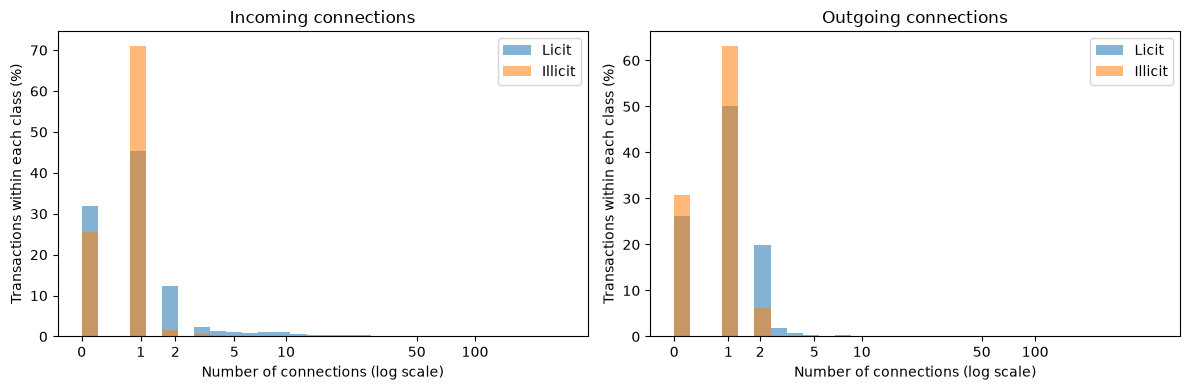

In [15]:
in_degree = edges.groupby('txId2').size()
out_degree = edges.groupby('txId1').size()
connectivity = train[['txId', 'label']].copy()
connectivity['in_degree'] = connectivity['txId'].map(in_degree).fillna(0)
connectivity['out_degree'] = connectivity['txId'].map(out_degree).fillna(0)
display(connectivity[['in_degree', 'out_degree']].describe().round(2))

# Use the same bins for both classes and compare percentages within each class.
labelled_connectivity = connectivity.loc[connectivity['label'].notna()]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, title in zip(axes, ['in_degree', 'out_degree'],
                            ['Incoming connections', 'Outgoing connections']):
    maximum = labelled_connectivity[column].max()
    bins = np.linspace(0, np.log1p(maximum) + 1e-9, 31)
    for value, name in [(0, 'Licit'), (1, 'Illicit')]:
        values = labelled_connectivity.loc[labelled_connectivity['label'].eq(value), column]
        weights = np.full(len(values), 100 / len(values))
        ax.hist(np.log1p(values), bins=bins, weights=weights, alpha=0.55, label=name)
    tick_counts = [count for count in [0, 1, 2, 5, 10, 50, 100, 500, 1000] if count <= maximum]
    ax.set_xticks(np.log1p(tick_counts), tick_counts)
    ax.set_title(title)
    ax.set_xlabel('Number of connections (log scale)')
    ax.set_ylabel('Transactions within each class (%)')
    ax.legend()
plt.tight_layout()
plt.show()

### **6.2 CORE Features and Fold Context**

`CORE` contains three simple graph features used by the four initial models trained in Section 7. The additional structural features and neighbour aggregates are described below.

| CORE column | What it measures |
|---|---|
| `out_degree` | Number of direct outgoing neighbours |
| `two_hop_out` | Number of distinct nodes reachable in exactly two directed steps, such as A → B → C |
| `component_size` | Number of nodes in the same connected group, treating edges as undirected |

`make_context(cut, batch_rows)` prepares the historical rows, batch features and graph for one fold. For example, `cut=16` with a batch covering steps 17–30 uses history through step 16, hides the batch labels and removes edges touching transactions known to occur after step 30. It returns these rows, the graph matrices and the three CORE columns for the later helpers to reuse.

In [16]:
CORE = ['out_degree', 'two_hop_out', 'component_size']


def make_context(cut, batch_rows):
    """
    Prepare historical rows, batch features and the three CORE graph columns.

    Hide batch labels and exclude edges touching nodes known to occur after
    the batch horizon. Untimed edge-only nodes remain in the supplied graph.
    """
    past = train.loc[train['time_step'] <= cut]
    # Drop batch labels before constructing inputs.
    batch = batch_rows[['txId', 'time_step', *FEATURES]].copy()
    visible = pd.concat([past[['txId', 'time_step', *FEATURES]], batch], ignore_index=True)
    horizon = int(batch['time_step'].max())
    future_ids = all_rows.loc[all_rows['time_step'] > horizon, 'txId']
    edge_list = edges.loc[~edges['txId1'].isin(future_ids) & ~edges['txId2'].isin(future_ids)]
    nodes = pd.Index(pd.unique(pd.concat([visible['txId'], edge_list['txId1'],
                                         edge_list['txId2']], ignore_index=True)))
    source = nodes.get_indexer(edge_list['txId1'])
    target = nodes.get_indexer(edge_list['txId2'])
    adjacency = sp.csr_matrix((np.ones(len(edge_list), dtype='float32'), (source, target)),
                              shape=(len(nodes), len(nodes)))
    adjacency.data[:] = 1
    undirected = adjacency.maximum(adjacency.T).tocsr()
    undirected.data[:] = 1
    two_hop = adjacency @ adjacency
    two_hop.data[:] = 1

    _, component = connected_components(undirected, directed=False)
    graph = pd.DataFrame({
        'out_degree': np.diff(adjacency.indptr),
        'two_hop_out': np.diff(two_hop.indptr),
        'component_size': np.bincount(component)[component],
    }, index=nodes).astype('float32')
    return {'cut': cut, 'past': past, 'fit': past.dropna(subset=['label']).copy(),
            'batch': batch, 'visible': visible, 'nodes': nodes,
            'a': adjacency, 'u': undirected, 'graph': graph}

### **6.3 Additional Structural Features**

Create 8 structural features for the prediction adjustments in Section 9. They describe incoming and outgoing connections, two-step paths and transaction chains.

A **parent** is an incoming neighbour; a **child** is an outgoing neighbour. **Selected** nodes are historical transactions with known labels or transactions being predicted together. **Other** nodes are the remaining graph nodes. Selected describes dataset membership, not illicit status.

| Feature | What it measures |
|---|---|
| `selected_in` | Incoming neighbours in the selected group |
| `other_in` | Incoming neighbours in the other group |
| `selected_share` | Share of incoming and outgoing connections touching selected nodes |
| `child_merge_mean` | Average number of other incoming connections per child |
| `out2_selected_paths` | Two-step outgoing paths ending at selected nodes |
| `single_output_parent_share` | Share of parents with exactly one outgoing connection |
| `forward_chain` | Chain length following nodes with one outgoing connection, capped at eight steps |
| `backward_chain` | Chain length following nodes with one incoming connection, capped at eight steps |

`structural_signals` returns these columns for the transactions being predicted. Section 9 uses them for fixed score adjustments; self-training uses only the original transaction features.

In [17]:
SIGNAL_COLUMNS = [
    'selected_in', 'other_in', 'selected_share', 'child_merge_mean', 'out2_selected_paths',
    'single_output_parent_share', 'forward_chain', 'backward_chain',
]


def structural_signals(context):
    order = np.argsort(context['nodes'].to_numpy())
    nodes = context['nodes'][order]
    a = context['a'][order][:, order].astype(float)
    at = a.T.tocsr()
    incoming = np.asarray(at.sum(axis=1)).ravel()
    outgoing = np.asarray(a.sum(axis=1)).ravel()
    selected = np.zeros(len(nodes))
    selected[nodes.get_indexer(np.r_[context['fit']['txId'], context['batch']['txId']])] = 1
    selected_in, selected_out = at @ selected, a @ selected

    def neighbour_mean(matrix, values, degree):
        return np.divide(matrix @ values, degree, out=np.full(len(nodes), np.nan), where=degree > 0)

    signals = {
        'selected_in': selected_in,
        'other_in': incoming - selected_in,
        'selected_share': (selected_in + selected_out) / np.maximum(incoming + outgoing, 1),
        'child_merge_mean': neighbour_mean(a, incoming - 1, outgoing),
        'out2_selected_paths': a @ selected_out,
        'single_output_parent_share': neighbour_mean(at, (outgoing == 1).astype(float), incoming),
    }
    for name, matrix, degree in [('forward_chain', a, outgoing), ('backward_chain', at, incoming)]:
        length = np.zeros(len(nodes))
        for _ in range(8):
            length = np.where(degree == 1, 1 + matrix @ length, 0)
        signals[name] = length
    return pd.DataFrame(signals, index=nodes).loc[context['batch']['txId'], SIGNAL_COLUMNS]

### **6.4 Neighbour Feature Aggregates**

`hop_features(context)` describes **what nearby transactions look like**, complementing the structural counts above.

For each of the 165 transaction features, it creates:

- `feat_*_h1`: a weighted combination of the transaction's own value and its direct neighbours' values.
- `feat_*_h2`: the result of mixing those values again, incorporating information from up to two connections away.

In [18]:
def hop_features(context, hops=2):
    """
    Mix feature values across neighbouring transactions.
    """
    nodes = context['nodes']
    keep = nodes.isin(context['visible']['txId'])
    indices = np.flatnonzero(keep)
    matrix = context['u'][indices][:, indices] + sp.identity(len(indices), format='csr', dtype='float32')
    degree = np.asarray(matrix.sum(axis=1)).ravel()
    normalised = sp.diags(degree ** -0.5) @ matrix @ sp.diags(degree ** -0.5)
    current = context['visible'].set_index('txId').loc[nodes[indices], FEATURES].to_numpy('float32')
    columns = {}
    for hop in range(1, hops + 1):
        current = normalised @ current
        columns.update({f'{column}_h{hop}': current[:, index] for index, column in enumerate(FEATURES)})
    return pd.DataFrame(columns, index=nodes[indices]).astype('float32')

### **6.5 Pruning, Graph Inputs and Feature Hops**

Compare raw-feature pruning thresholds, then add the three CORE columns at a fixed threshold of 0.95. The hop variants also include neighbour aggregates of all 165 features, calculated for one and two hops.

The correlated pairs in Section 3.7 motivate pruning. `prune_columns` keeps the feature most strongly associated with the training label, removes its highly correlated alternatives, and repeats within each fold. `input_matrices` prunes raw and optional hop columns first, then appends all three CORE columns.

In [19]:
def prune_columns(frame, labels, threshold=0.95):
    """
    Select features while removing strongly correlated alternatives.
    """
    strength = frame.corrwith(labels).abs().fillna(-1)
    correlation = frame.corr().abs()
    remaining, selected = set(frame.columns), []
    while remaining:
        chosen = sorted(remaining, key=lambda column: (-strength[column], column))[0]
        selected.append(chosen)
        remove = set(correlation.index[correlation.loc[chosen] >= threshold])
        remaining -= remove | {chosen}
    return selected


def input_matrices(context, threshold=0.95, include_graph=True, hops=0, include_time=False):
    """
    Prune raw and optional hop columns, then append all three CORE columns.

    Use include_graph=False for raw-only comparisons. CORE columns are kept
    outside pruning; the default correlation threshold is 0.95.
    """
    fit = context['fit'].set_index('txId')
    batch = context['batch'].set_index('txId')
    x_fit, x_batch = fit[FEATURES], batch[FEATURES]
    if hops:
        hop_table = hop_features(context, hops)
        x_fit = x_fit.join(hop_table)
        x_batch = x_batch.join(hop_table)
    labels = fit['label'].astype(int)
    columns = x_fit.columns.tolist() if threshold is None else prune_columns(x_fit, labels, threshold)
    x_fit, x_batch = x_fit[columns], x_batch[columns]
    if include_time:
        x_fit = x_fit.join(fit[['time_step']])
        x_batch = x_batch.join(batch[['time_step']])
    if include_graph:
        graph = context['graph'][CORE]
        x_fit, x_batch = x_fit.join(graph), x_batch.join(graph)
    return x_fit.fillna(0), x_batch.fillna(0)

In [20]:
feature_specs = [
    ('All raw features', dict(threshold=None, include_graph=False)),
    ('Pruned raw, 0.99', dict(threshold=0.99, include_graph=False)),
    ('Pruned raw, 0.95', dict(threshold=0.95, include_graph=False)),
    ('Pruned raw, 0.90', dict(threshold=0.90, include_graph=False)),
    ('Pruned + core graph', dict(include_graph=True)),
    ('Pruned + one-hop + core graph', dict(hops=1)),
    ('Pruned + two-hop + core graph', dict(hops=2)),
]
for fold in FOLDS:
    context = make_context(fold['cut'], fold['validation'])
    fit = context['fit']
    for name, settings in feature_specs:
        x_fit, x_batch = input_matrices(context, **settings)
        model = HistGradientBoostingClassifier(**HGB_BASE).fit(
            x_fit, fit['label'].astype(int), sample_weight=sample_weights(fit['label'], fit['time_step']))
        record('Features', name, fold, model.predict_proba(x_batch)[:, 1], x_fit.shape[1])
    print(f'Feature fold {fold["cut"]} complete.', flush=True)
    del context
    gc.collect()
show_results('Features')

Feature fold 16 complete.
Feature fold 17 complete.
Feature fold 18 complete.
Feature fold 19 complete.
Feature fold 20 complete.
Feature fold 21 complete.


,mean_auc,std_auc,mean_ap,folds
experiment,,,,
"Pruned raw, 0.95",0.89504,0.02397,0.81770,6
"Pruned raw, 0.90",0.89112,0.01689,0.81460,6
Pruned + core graph,0.88945,0.02623,0.81559,6
Pruned + one-hop + core graph,0.87878,0.01734,0.81098,6
"Pruned raw, 0.99",0.87739,0.01924,0.81010,6
Pruned + two-hop + core graph,0.87215,0.02740,0.80790,6
All raw features,0.87161,0.02054,0.80858,6


Highest mean ROC-AUC in this comparison: **Pruned raw, 0.95** (0.89504).

Pruning at 0.95 improves mean ROC-AUC from **0.87161** with all raw features to **0.89504**, the best result in this
comparison. Adding the three CORE graph features lowers it to **0.88945** with these HGB settings, and the one-hop
(**0.89440**) and two-hop (**0.89373**) variants also score slightly below pruned raw features alone. The graph inputs
therefore do not improve this HGB comparison. The models in Section 7 nonetheless keep the three CORE features, and the
hop NN uses the neighbour aggregates, to test whether graph information helps the final models and the ensemble in
Sections 7–8.

| Model | Inputs used |
|---|---|
| HGB, plain NN and LightGBM | Raw features pruned at 0.95, plus all three CORE features |
| Hop NN | Raw and one-/two-hop features pruned together at 0.95, plus all three CORE features |

### **6.6 Distance and Similarity Measurements**

Use the correlation-pruned features to measure how similar transactions are. `prune_columns` from Section 6.5,
fitted on the historical labelled rows, removes near-duplicate columns so they do not dominate the distances.
Fit the feature transformation on the same rows, then calculate distances for the transactions being predicted together.

| Measurement | What it describes |
|---|---|
| `density` | How close a transaction is to its ten nearest neighbours among the prediction rows |
| `log_nearest` | Log distance to the nearest other prediction row, relative to the batch's typical neighbour distance |
| `novelty` | Log distance to the tenth nearest historical labelled row minus log distance to the tenth nearest other prediction row |
| `copayee_distance` | Distance from the average features of other visible transactions paying into a shared destination |
| `neighbours`, `kernel` | Similar transaction indices and their weights for feature-space smoothing |
| `edges` | Connections between prediction rows, with direct links weighted 1 and two-hop links weighted 0.2 |

`batch_information(context)` prepares these measurements and links. Section 9 uses them to adjust
and smooth the blended predictions.

In [21]:
def batch_information(context):
    """Prepare distance signals, neighbour weights and graph links for prediction rows.

    Select non-redundant features with prune_columns and fit feature scaling on
    historical labelled rows. Return measurements used
    by Section 9 to adjust and smooth predictions.
    """
    fit, batch = context['fit'], context['batch']
    columns = prune_columns(fit[FEATURES], fit['label'].astype(int))
    scaler = QuantileTransformer(output_distribution='normal', random_state=0).fit(fit[columns])
    z_fit = scaler.transform(fit[columns])
    z_batch = scaler.transform(batch[columns])
    distances, neighbours = NearestNeighbors(n_neighbors=11).fit(z_batch).kneighbors(z_batch)
    distances, neighbours = distances[:, 1:], neighbours[:, 1:]
    median_distance = max(float(np.median(distances)), 1e-12)
    density = np.exp(-(distances / (0.5 * median_distance)) ** 2).mean(axis=1)
    log_nearest = np.log(distances[:, :1] / median_distance + 1e-3).mean(axis=1)
    kernel = np.exp(-(distances / median_distance) ** 2)
    kernel /= np.maximum(kernel.sum(axis=1, keepdims=True), 1e-12)

    historical = NearestNeighbors(n_neighbors=10, algorithm='brute', n_jobs=2).fit(
        z_fit.astype('float32')).kneighbors(z_batch.astype('float32'))[0]
    batch_distances, batch_indices = NearestNeighbors(n_neighbors=11, algorithm='brute', n_jobs=2).fit(
        z_batch.astype('float32')).kneighbors(z_batch.astype('float32'))
    batch_distances = np.where(batch_indices == np.arange(len(batch))[:, None], np.inf, batch_distances)
    batch_distances = np.sort(batch_distances, axis=1)[:, :10]
    novelty = np.log(historical[:, 9] + 1e-3) - np.log(batch_distances[:, 9] + 1e-3)

    order = np.argsort(context['nodes'].to_numpy())
    nodes = context['nodes'][order]
    a = context['a'][order][:, order].astype(float)
    rows = nodes.get_indexer(batch['txId'])
    copayees = (a[rows] @ a.T).tocoo()
    keep = copayees.col != rows[copayees.row]
    copayees = sp.csr_matrix((copayees.data[keep], (copayees.row[keep], copayees.col[keep])), shape=copayees.shape)
    copayees.data[:] = 1
    visible = context['visible'].drop_duplicates('txId')
    copayees = copayees[:, nodes.get_indexer(visible['txId'])]
    count = np.asarray(copayees.sum(axis=1)).ravel()
    centres = (copayees @ scaler.transform(visible[columns])) / np.maximum(count, 1)[:, None]
    copayee_distance = np.linalg.norm(z_batch - centres, axis=1)
    copayee_distance[count == 0] = np.nan

    direct = (a + a.T).tocsr()[rows][:, rows].tocsr()
    direct.setdiag(0)
    direct.eliminate_zeros()
    direct.data[:] = 1
    undirected = ((a + a.T) > 0).astype(float)
    two_hop = (undirected @ undirected).tocsr()[rows][:, rows].tocsr()
    two_hop.setdiag(0)
    two_hop.eliminate_zeros()
    two_hop.data[:] = 1
    return {'density': density, 'log_nearest': log_nearest, 'novelty': novelty,
            'copayee_distance': copayee_distance, 'neighbours': neighbours, 'kernel': kernel,
            'edges': direct + 0.2 * two_hop}

## **7. Model Training**

HGB uses the pruned raw features and three CORE features, with seven leaves and 300 boosting iterations.
Illicit transactions receive more weight, and a recency half-life of 14 favours recent transactions.
`HGB_CANDIDATE` stores these fixed tree settings.

We train two neural networks with different inputs:

| Network | Inputs |
|---|---|
| Plain NN | Pruned original transaction features + three CORE graph features |
| Hop NN | Original, one-hop and two-hop features pruned together + three CORE graph features |

Both use correlation pruning at **0.95**, with all three CORE features added afterwards.
The networks have the same structure and input transformation. Illicit transactions receive more training
weight, and a transaction 21 time steps older receives half the weight.

We also compare LightGBM trained with:

- Only licit and illicit transactions.
- Licit, illicit and unlabelled transactions, treating “unknown” as a third class.

The unknown rows together receive **30% of the weight given to labelled rows**. Predictions rank transactions
by how strongly the model favours illicit over licit. LightGBM settings (`LGB_PARAMS`) stay the same in both
versions so we can measure whether including unknown rows helps.

`rank_score` puts each model's predictions on a common ranking scale before the blends in Section 8.

In [22]:
HGB_CANDIDATE = {**HGB_BASE, 'max_leaf_nodes': 7, 'l2_regularization': 3.0}

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=15,
                  min_child_samples=50, reg_lambda=3.0, random_state=SEED,
                  n_jobs=1, verbosity=-1, deterministic=True, force_col_wise=True)

Sections 5-6 used `HGB_BASE` (31 leaves, L2 1.0) with every training row weighted equally over time. Before training the final models, compare it with `HGB_CANDIDATE` (7 leaves, L2 3.0), each with no recency weighting and with half-lives of 14 and 21 time steps. All six variants use the inputs chosen in Section 6.5: raw features pruned at 0.95 plus the three CORE features.

In [23]:
hgb_settings = [
    ('Base settings, no recency', HGB_BASE, None),
    ('Base settings, half-life 14', HGB_BASE, 14),
    ('Base settings, half-life 21', HGB_BASE, 21),
    ('Candidate settings, no recency', HGB_CANDIDATE, None),
    ('Candidate settings, half-life 14', HGB_CANDIDATE, 14),
    ('Candidate settings, half-life 21', HGB_CANDIDATE, 21),
]
for fold in FOLDS:
    context = make_context(fold['cut'], fold['validation'])
    fit = context['fit']
    x_fit, x_batch = input_matrices(context)
    for name, parameters, half_life in hgb_settings:
        model = HistGradientBoostingClassifier(**parameters).fit(
            x_fit, fit['label'].astype(int), sample_weight=sample_weights(fit['label'], fit['time_step'], half_life))
        record('HGB settings', name, fold, model.predict_proba(x_batch)[:, 1], x_fit.shape[1])
    print(f'HGB settings fold {fold["cut"]} complete.', flush=True)
    del context
    gc.collect()
show_results('HGB settings')

HGB settings fold 16 complete.
HGB settings fold 17 complete.
HGB settings fold 18 complete.
HGB settings fold 19 complete.
HGB settings fold 20 complete.
HGB settings fold 21 complete.


,mean_auc,std_auc,mean_ap,folds
experiment,,,,
"Candidate settings, half-life 21",0.94337,0.00946,0.84721,6
"Candidate settings, half-life 14",0.93978,0.01191,0.84340,6
"Candidate settings, no recency",0.93890,0.01131,0.84287,6
"Base settings, half-life 21",0.89376,0.01619,0.81669,6
"Base settings, half-life 14",0.89077,0.01064,0.81489,6
"Base settings, no recency",0.88945,0.02623,0.81559,6


Highest mean ROC-AUC in this comparison: **Candidate settings, half-life 21** (0.94337).

**Findings:** The tree settings matter far more than recency weighting. `HGB_CANDIDATE` (7 leaves, L2 3.0) scores
between **0.93890** and **0.94337**, against 0.88945–0.89376 for `HGB_BASE` (31 leaves, L2 1.0): shallower, more
regularised trees generalise better to later time steps. Recency weighting helps both settings. With the candidate
settings, a half-life of 21 scores best (**0.94337**), a half-life of 14 scores 0.93978 and no recency weighting 0.93890.
The models below use `HGB_CANDIDATE` with a half-life of 14, which is 0.0036 below the half-life of 21 in this
comparison.

In [24]:
class TransactionNet(nn.Module):
    def __init__(self, n_features, hidden=128, dropout=0.3):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(n_features, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
        )
        self.output = nn.Linear(hidden + n_features, 1)

    def forward(self, values):
        return self.output(torch.cat([self.body(values), values], dim=1)).squeeze(1)


def rank_score(values):
    """
    Put a batch of model scores on a common ranking scale.

    Accept a one-dimensional array of finite scores. Rank them from smallest
    to largest and divide by the number of rows. Tied values receive their
    average rank, and the returned array keeps the original row order.

    The resulting scores express relative position within the batch and are
    used to combine models whose original score scales differ.
    """
    return rankdata(values) / len(values)


def fit_network(x_fit, labels, weights, x_batch, seeds):
    scaler = QuantileTransformer(output_distribution='normal', random_state=0).fit(x_fit)
    train_tensor = torch.tensor(scaler.transform(x_fit), dtype=torch.float32)
    batch_tensor = torch.tensor(scaler.transform(x_batch), dtype=torch.float32)
    label_tensor = torch.tensor(np.asarray(labels), dtype=torch.float32)
    weight_tensor = torch.tensor(weights, dtype=torch.float32)
    seed_scores = []
    for seed in range(seeds):
        torch.manual_seed(seed)
        model = TransactionNet(x_fit.shape[1])
        optimiser = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=5e-4)
        for _ in range(NET_EPOCHS):
            model.train()
            optimiser.zero_grad()
            losses = nn.functional.binary_cross_entropy_with_logits(
                model(train_tensor), label_tensor, reduction='none')
            ((losses * weight_tensor).sum() / weight_tensor.sum()).backward()
            optimiser.step()
        model.eval()
        with torch.no_grad():
            seed_scores.append(rank_score(model(batch_tensor).numpy()))
    return np.mean(seed_scores, axis=0)


def fit_lightgbm(context, x_fit, x_batch, include_unknown=True):
    fit = context['fit']
    weights = sample_weights(fit['label'], fit['time_step'], 14)
    if not include_unknown:
        model = lgb.LGBMClassifier(**LGB_PARAMS).fit(x_fit, fit['label'].astype(int), sample_weight=weights)
        return rank_score(model.predict_proba(x_batch)[:, 1])
    unknown = context['past'].loc[context['past']['label'].isna()]
    raw_columns = [column for column in x_fit if column in FEATURES]
    x_unknown = (unknown.set_index('txId')[raw_columns].join(context['graph'][CORE])
                  .fillna(0)[x_fit.columns])
    unknown_weights = np.exp(-np.log(2) * (fit['time_step'].max() - unknown['time_step'].to_numpy()) / 14)
    unknown_weights *= 0.3 * weights.sum() / unknown_weights.sum()
    values = np.vstack([x_fit.to_numpy(), x_unknown.to_numpy()])
    labels = np.r_[fit['label'].to_numpy(dtype=int), np.full(len(unknown), 2)]
    model = lgb.LGBMClassifier(**LGB_PARAMS, objective='multiclass', num_class=3).fit(
        values, labels, sample_weight=np.r_[weights, unknown_weights])
    logits = model.predict(x_batch.to_numpy(), raw_score=True)
    return rank_score(logits[:, 1] - logits[:, 0])


def base_predictions(context, net_seeds, include_binary=False):
    fit = context['fit']
    x_fit, x_batch = input_matrices(context)
    weights = sample_weights(fit['label'], fit['time_step'], 14)
    hgb = HistGradientBoostingClassifier(**HGB_CANDIDATE).fit(
        x_fit, fit['label'].astype(int), sample_weight=weights)
    result = {'HGB component': rank_score(hgb.predict_proba(x_batch)[:, 1])}
    net_weights = sample_weights(fit['label'], fit['time_step'], 21)
    result['Plain network'] = fit_network(x_fit, fit['label'], net_weights, x_batch, net_seeds)
    print(f'  Plain network: {net_seeds} seeds complete.', flush=True)
    hop_fit, hop_batch = input_matrices(context, hops=2)
    result['Hop network'] = fit_network(hop_fit, fit['label'], net_weights, hop_batch, net_seeds)
    print(f'  Hop network: {net_seeds} seeds complete.', flush=True)
    result['Three-class LightGBM'] = fit_lightgbm(context, x_fit, x_batch)
    if include_binary:
        result['Binary LightGBM'] = fit_lightgbm(context, x_fit, x_batch, include_unknown=False)
    sizes = {'HGB inputs': x_fit.shape[1], 'Hop-network inputs': hop_fit.shape[1]}
    return result, sizes


for fold in FOLDS:
    print(f'Model fold {fold["cut"]}', flush=True)
    context = make_context(fold['cut'], fold['validation'])
    components, sizes = base_predictions(context, VALIDATION_NET_SEEDS, include_binary=True)
    for name, scores in components.items():
        count = sizes['Hop-network inputs'] if name == 'Hop network' else sizes['HGB inputs']
        record('Models', name, fold, scores, count)
    del context
    gc.collect()
show_results('Models')

Model fold 16
  Plain network: 3 seeds complete.
  Hop network: 3 seeds complete.
Model fold 17
  Plain network: 3 seeds complete.
  Hop network: 3 seeds complete.
Model fold 18
  Plain network: 3 seeds complete.
  Hop network: 3 seeds complete.
Model fold 19
  Plain network: 3 seeds complete.
  Hop network: 3 seeds complete.
Model fold 20
  Plain network: 3 seeds complete.
  Hop network: 3 seeds complete.
Model fold 21
  Plain network: 3 seeds complete.
  Hop network: 3 seeds complete.


,mean_auc,std_auc,mean_ap,folds
experiment,,,,
Three-class LightGBM,0.94932,0.00860,0.85617,6
Plain network,0.94092,0.02114,0.85021,6
HGB component,0.93978,0.01191,0.84340,6
Hop network,0.92075,0.02607,0.83393,6
Binary LightGBM,0.91474,0.01191,0.82660,6


Highest mean ROC-AUC in this comparison: **Three-class LightGBM** (0.94932).

**Findings:** The three-class LightGBM is the strongest single model (**0.94932**), ahead of the hop network (0.94224), the plain network (0.94092) and HGB (0.93978). Treating unlabelled rows as a third class matters: the binary LightGBM with the same settings scores **0.91474**, so including the unknown rows adds 0.035 ROC-AUC. The hop network has the highest average precision (0.85870) but the largest spread across folds (standard deviation 0.023). The three-class LightGBM is carried into the blends in Section 8; the binary version is not used further.

## **8. Ensemble Experiments**

We combine the models' prediction ranks so their scores are on the same scale.

The three-model blend assigns 70% to HGB and 15% to each neural network.

For the four-model blend, we transfer 20% of HGB's share to LightGBM:

- LightGBM receives 0.70 × 0.20 = **0.14**.
- HGB keeps 0.70 − 0.14 = **0.56**.
- Each neural network keeps **0.15**.

| Model | Three-model blend | Four-model blend |
|---|---:|---:|
| HGB | 0.70 | 0.56 |
| Three-class LightGBM | 0 | 0.14 |
| Plain NN | 0.15 | 0.15 |
| Hop NN | 0.15 | 0.15 |

The experiments below compare equal weights, the three-model blend, and replacing 10%, 20% or 30% of HGB's share with LightGBM.

In [25]:
def ensemble_scores(components):
    hgb = components['HGB component']
    plain = components['Plain network']
    hop = components['Hop network']
    lightgbm = components['Three-class LightGBM']
    tree_blend = 0.70 * hgb + 0.15 * plain + 0.15 * hop
    return {
        'Equal-weight three-model blend': (hgb + plain + hop) / 3,
        'Tree-heavy three-model blend': tree_blend,
        '10% HGB replacement': tree_blend + 0.70 * 0.10 * (lightgbm - hgb),
        'Four-model blend': tree_blend + 0.70 * 0.20 * (lightgbm - hgb),
        '30% HGB replacement': tree_blend + 0.70 * 0.30 * (lightgbm - hgb),
    }


for fold in FOLDS:
    bank = predictions[fold['cut']]
    for name, scores in ensemble_scores(bank).items():
        record('Ensembles', name, fold, scores)
show_results('Ensembles')

model_names = ['HGB component', 'Plain network', 'Hop network', 'Three-class LightGBM']
correlations = [pd.DataFrame({name: predictions[fold['cut']][name] for name in model_names}).corr(method='spearman')
                for fold in FOLDS]
display((sum(correlations) / len(correlations)).round(3))

,mean_auc,std_auc,mean_ap,folds
experiment,,,,
30% HGB replacement,0.95081,0.01451,0.86296,6
Four-model blend,0.94994,0.01482,0.86180,6
Equal-weight three-model blend,0.94927,0.01858,0.86395,6
10% HGB replacement,0.94899,0.01513,0.86052,6
Tree-heavy three-model blend,0.94795,0.01543,0.85912,6


Highest mean ROC-AUC in this comparison: **30% HGB replacement** (0.95081).

,HGB component,Plain network,Hop network,Three-class LightGBM
HGB component,1.000,0.707,0.578,0.905
Plain network,0.707,1.000,0.766,0.703
Hop network,0.578,0.766,1.000,0.552
Three-class LightGBM,0.905,0.703,0.552,1.000


**Findings:** Every blend beats every single model (the best single model, three-class LightGBM, scores 0.94932). The equal-weight three-model blend has the highest mean ROC-AUC (**0.95341**), followed by 30% HGB replacement (0.95280) and the four-model blend with 20% replacement (0.95196). The Spearman correlations show why blending helps: HGB and LightGBM rank transactions very similarly (0.905), while the networks are less correlated with HGB (0.618–0.707).

The final pipeline uses the **four-model blend with 20% replacement**, giving HGB an effective weight of **0.56**.

## **9. Prediction Refinement**

Start with the four-model blend from Section 8. Use the structural features from Section 6.3 and
the distance and similarity measurements from Section 6.6 to adjust its predictions.
Self-training below uses only the original transaction features.

### **9.1 Score Adjustments and Smoothing**

Apply fixed adjustments using the prepared measurements, then mix scores with those of similar
or connected transactions.

| Function | How it changes predictions |
|---|---|
| `adjust` | Raises or lowers scores using a structural feature or distance measurement and a fixed strength |
| `feature_smooth` | Mixes scores with those of similar transactions, using the neighbour weights from Section 6.6 |
| `graph_smooth` | Mixes scores along direct and two-hop payment links prepared in Section 6.6 |
| `time_shift` | Raises or lowers scores using the average prediction for each time step |

`score_logit` converts scores to a scale where adjustments can be added or subtracted.
`normal_rank` puts adjustment signals on a comparable scale so their original units do not determine their influence.

In [26]:
def score_logit(scores):
    """
    Convert scores to the logit scale for adjustment and smoothing.

    Clip the input scores to [0.0001, 0.9999], then return log(p / (1 - p))
    for each clipped score p. Clipping prevents infinite values at 0 and 1.
    A score of 0.5 maps to zero; larger scores map to positive values.
    """
    return logit(np.clip(scores, 1e-4, 1 - 1e-4))


def normal_rank(values):
    """
    Map an adjustment signal's ranks to normal-distribution quantiles.
    """
    values = np.asarray(values, dtype=float)
    valid = np.isfinite(values)
    result = np.zeros(len(values))
    result[valid] = norm.ppf(rankdata(values[valid]) / (valid.sum() + 1))
    return result

In [27]:
def adjust(scores, values, strength):
    return rank_score(score_logit(scores) - strength * normal_rank(values))


def feature_smooth(scores, information, alpha=0.15):
    original = score_logit(scores)
    current = original.copy()
    for _ in range(10):
        current = (1 - alpha) * original + alpha * (
            information['kernel'] * current[information['neighbours']]).sum(axis=1)
    return rank_score(current)


def graph_smooth(scores, matrix, alpha=0.1):
    degree = np.asarray(matrix.sum(axis=1)).ravel()
    normalised = sp.diags(1 / np.where(degree > 0, degree, 1)) @ matrix
    original = score_logit(scores)
    current = original.copy()
    for _ in range(10):
        current = np.where(degree > 0, (1 - alpha) * original + alpha * (normalised @ current), original)
    return rank_score(current)


def time_shift(scores, steps, strength=0.2):
    logits = score_logit(scores)
    means = pd.Series(logits).groupby(np.asarray(steps)).transform('mean').to_numpy()
    return rank_score(logits + strength * (means - logits.mean()))

### **9.2 Self-training**

We use the existing prediction scores to create temporary labels:

- The highest-scoring 10% are treated as illicit.
- The lowest-scoring 60% are treated as licit.
- The middle 30% are left out of training because their predictions are less certain.

We train another HGB using these guessed labels and the original transaction features.

Each transaction receives a prediction from a model that did not train on that transaction. We repeat this with three random seeds, average the predictions, and combine them with the existing scores.

In [28]:
def self_train(scores, batch):
    values = batch[FEATURES].to_numpy()
    ranks = rank_score(scores)
    positive, negative = ranks >= 0.90, ranks <= 0.60
    use = positive | negative
    labels = positive.astype(int)
    seed_scores = []
    for seed in (0, 1, 2):
        out = np.zeros(len(scores))
        splitter = StratifiedKFold(5, shuffle=True, random_state=seed)
        for fit_index, score_index in splitter.split(np.arange(len(scores)), labels + 2 * use):
            selected = fit_index[use[fit_index]]
            model = HistGradientBoostingClassifier(
                max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                l2_regularization=1.0, random_state=seed).fit(values[selected], labels[selected])
            out[score_index] = model.predict_proba(values[score_index])[:, 1]
        seed_scores.append(rank_score(out))
    return np.mean(seed_scores, axis=0)


def blend_self_training(scores, learnt_scores, weight=0.4):
    return rank_score(score_logit(scores) + weight * score_logit(np.clip(learnt_scores, 1e-3, 1 - 1e-3)))

### **9.3 Run the Complete Refinement Pipeline**

Run every refinement in the order below, then apply self-training with a weight of **0.4**.
All adjustment strengths and repeated smoothing steps are retained.

For validation, run this same pipeline on each temporal fold and record AUC after each stage.


In [29]:
def refine_scores(base, signals, information, steps):
    """Apply every score refinement in order and return the intermediate scores."""
    stages = {'Four-model blend': base.copy()}
    current = base.copy()

    # Density and context adjustments.
    current = rank_score(score_logit(current) - 0.2 * information['density'] + 0.2 * information['log_nearest'])
    stages['Density adjustment'] = current.copy()
    for column, strength in [('selected_share', 0.2), ('selected_in', 0.2),
                              ('other_in', 0.1), ('other_in', 0.1)]:
        current = adjust(current, signals[column], strength)
    current = adjust(current, information['copayee_distance'], 0.1)
    current = adjust(current, signals['backward_chain'], 0.2)
    current = adjust(current, information['novelty'], 0.1)
    stages['Context adjustments'] = current.copy()

    # Smooth predictions in feature space and along graph connections.
    current = feature_smooth(current, information)
    stages['Feature-space smoothing'] = current.copy()
    current = graph_smooth(current, information['edges'], 0.1)
    stages['Graph smoothing'] = current.copy()
    current = adjust(current, signals['child_merge_mean'], -0.25)
    current = adjust(current, signals['selected_share'], 0.1)
    current = graph_smooth(current, information['edges'], 0.05)
    stages['Structural adjustment and smoothing'] = current.copy()

    # Apply the remaining structural and time-step adjustments.
    current = adjust(current, signals['out2_selected_paths'], 0.2)
    current = time_shift(current, steps)
    current = adjust(current, signals['forward_chain'], 0.1)
    current = adjust(current, signals['backward_chain'], 0.1)
    current = time_shift(current, steps)
    current = adjust(current, signals['single_output_parent_share'], 0.1)
    stages['Full adjustment chain'] = current.copy()
    return stages


for fold in FOLDS:
    print(f'Refinement fold {fold["cut"]}', flush=True)
    context = make_context(fold['cut'], fold['validation'])
    signals = structural_signals(context)
    information = batch_information(context)
    base = predictions[fold['cut']]['Four-model blend']
    stages = refine_scores(base, signals, information, context['batch']['time_step'])
    for name, scores in stages.items():
        record('Refinement', name, fold, scores)
    starting_scores = stages['Full adjustment chain']
    pseudo_scores = self_train(starting_scores, context['batch'])
    complete_scores = blend_self_training(starting_scores, pseudo_scores, weight=0.4)
    record('Refinement', 'Complete pipeline', fold, complete_scores)
    del context, signals, information
    gc.collect()
show_results('Refinement')


Refinement fold 16
Refinement fold 17
Refinement fold 18
Refinement fold 19
Refinement fold 20
Refinement fold 21


,mean_auc,std_auc,mean_ap,folds
experiment,,,,
Four-model blend,0.94994,0.01482,0.86180,6
Density adjustment,0.92445,0.01911,0.82963,6
Graph smoothing,0.89110,0.02244,0.79607,6
Feature-space smoothing,0.88791,0.02204,0.79103,6
Context adjustments,0.88382,0.02150,0.77370,6
Structural adjustment and smoothing,0.87508,0.02247,0.78185,6
Full adjustment chain,0.85074,0.02116,0.76219,6
Complete pipeline,0.83774,0.02731,0.77945,6


Highest mean ROC-AUC in this comparison: **Four-model blend** (0.94994).

**Findings:** On the temporal folds every refinement stage scores below the four-model blend (**0.95196**): density adjustment 0.92616, context adjustments 0.88609, structural adjustment and smoothing 0.87721, and the full adjustment chain 0.85256. The complete pipeline with self-training scores **0.83668**, 0.115 below the blend. The two smoothing steps are the only stages that raise ROC-AUC relative to the stage before them (+0.004 and +0.003). Although this validation does not support the refinement settings, the final model applies them.

## **10. Final Training and Submission**

Fit on all known training labels, use the unknown training rows in the three-class model, and apply the complete refinement chain to the test batch. This cell only trains and predicts; the next cell writes the CSV.

### **10.1 Final Model**

| Part | Setting |
|---|---|
| Inputs | Correlation pruning at 0.95, then all three CORE graph columns: `out_degree`, `two_hop_out`, `component_size` |
| HGB | 7 leaves, 300 iterations, learning rate 0.06, L2 regularisation 3.0; rows weighted by recency (half-life 14 time steps) and inverse class frequency |
| Plain network | Pruned features + CORE; two hidden layers of 128 units, dropout 0.3, 150 epochs, recency half-life 21; 40 seeds averaged |
| Hop network | Same architecture and training, with one- and two-hop neighbour features of all 165 features added to its inputs |
| Three-class LightGBM | Pruned features + CORE; 400 trees, 15 leaves, learning rate 0.05, L2 regularisation 3.0. Classes: licit, illicit and unknown (unlabelled training rows). Labelled rows are weighted by recency (half-life 14) and inverse class frequency; the unknown rows together receive 30% of the labelled rows' total weight. Scored by the illicit-vs-licit log-odds |
| Blend | 0.56 HGB + 0.14 LightGBM + 0.15 plain network + 0.15 hop network |
| Refinement | Density and structural adjustments, feature and graph smoothing, time-step shifts |
| Self-training | Top 10% and bottom 60%; five folds, three seeds, blend weight 0.4 |

The output is a ranking score between 0 and 1.

In [30]:
final_context = make_context(int(train['time_step'].max()), test)
final_components, final_sizes = base_predictions(final_context, FINAL_NET_SEEDS)
display(pd.Series(final_sizes, name='features').to_frame())

final_base = ensemble_scores(final_components)['Four-model blend']
final_signals = structural_signals(final_context)
final_information = batch_information(final_context)
final_stages = refine_scores(final_base, final_signals, final_information, test['time_step'])
final_start = final_stages['Full adjustment chain']
final_pseudo = self_train(final_start, final_context['batch'])
final_scores = blend_self_training(final_start, final_pseudo)

print(f'{len(final_scores):,} test scores.')

  Plain network: 40 seeds complete.
  Hop network: 40 seeds complete.


,features
HGB inputs,108
Hop-network inputs,279


15,329 test scores.


In [31]:
submission = sample.copy()
submission['target'] = final_scores

output_directory = ROOT / 'submissions'
output_directory.mkdir(exist_ok=True)
submission_path = output_directory / 'submission_final.csv'
submission.to_csv(submission_path, index=False)
print(f'Saved {submission_path.relative_to(ROOT)}')
display(submission.head())

Saved submissions/submission_final.csv


,index,target
0,0,0.643943
1,1,0.623915
2,2,0.533368
3,3,0.646487
4,4,0.382869


### **10.2 Validation Performance of the Final Recipe**

,roc_auc,accuracy,precision,recall,f1
fold,,,,,
16,0.8811,0.9239,0.9885,0.5119,0.6745
17,0.8579,0.9190,0.9591,0.5027,0.6596
18,0.8321,0.9102,0.9743,0.4800,0.6431
19,0.8325,0.9133,0.9843,0.4922,0.6562
20,0.8120,0.9258,0.9234,0.5636,0.7000
21,0.8109,0.9309,0.9296,0.5883,0.7206
mean,0.8377,0.9205,0.9599,0.5231,0.6757


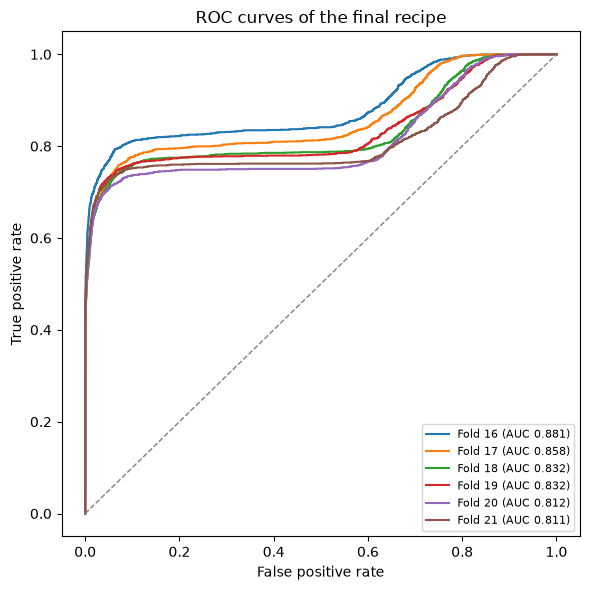

In [32]:
rows = []
fig, ax = plt.subplots(figsize=(6, 6))
for fold in FOLDS:
    labels = fold['validation']['label'].astype(int)
    scores = predictions[fold['cut']]['Complete pipeline']
    flagged = (rank_score(scores) > 1 - fold['fit']['label'].mean()).astype(int)
    rows.append({'fold': fold['cut'], 'roc_auc': roc_auc_score(labels, scores),
                 'accuracy': accuracy_score(labels, flagged),
                 'precision': precision_score(labels, flagged, zero_division=0),
                 'recall': recall_score(labels, flagged, zero_division=0),
                 'f1': f1_score(labels, flagged, zero_division=0)})
    fpr, tpr, _ = roc_curve(labels, scores)
    ax.plot(fpr, tpr, label=f'Fold {fold["cut"]} (AUC {rows[-1]["roc_auc"]:.3f})')

final_metrics = pd.DataFrame(rows).set_index('fold')
final_metrics.loc['mean'] = final_metrics.mean()
display(final_metrics.round(4))

ax.plot([0, 1], [0, 1], color='grey', linestyle='--', linewidth=1)
ax.set(title='ROC curves of the final recipe', xlabel='False positive rate', ylabel='True positive rate')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()